<a href="https://colab.research.google.com/github/junkim-researcher/turboquant-study1/blob/main/notebooks/exp2_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2단계: 어텐션 실험 (실제 언어모델 Qwen2.5-0.5B)

## ⚠️ 실행 전에 GPU 켜기
메뉴 **[런타임] → [런타임 유형 변경] → 하드웨어 가속기 `T4 GPU` → [저장]**

그다음 **[런타임] → [모두 실행]** (약 5~15분, 모델과 데이터를 내려받는 시간 포함)

끝나면 **[파일] → [GitHub에 사본 저장]** → 경로 `notebooks/exp2_colab.ipynb` 그대로 → **[확인]**

> Hugging Face 토큰 관련 경고(HF_TOKEN)가 떠도 무시해도 됩니다. 공개 모델이라 토큰 없이 받아집니다.

In [1]:
# 1) GPU 확인
!nvidia-smi -L || echo '⚠️ GPU가 없습니다. [런타임]→[런타임 유형 변경]에서 T4 GPU를 켜고 다시 실행하세요. (CPU로도 돌아가지만 30분 이상 걸립니다)'

GPU 0: Tesla T4 (UUID: GPU-6a57add9-bb5f-496d-b902-5c7c2d8bfbdd)


In [2]:
# 2) 코드 내려받기
!rm -rf /content/turboquant-study1
!git clone -q https://github.com/junkim-researcher/turboquant-study1.git /content/turboquant-study1
%cd /content/turboquant-study1
!git log --oneline -1

/content/turboquant-study1
56be314 (HEAD -> main, origin/main, origin/HEAD) 2단계: 어텐션 실험 코드와 GPU용 Colab 노트북


In [3]:
# 3) 글꼴과 라이브러리 준비
!apt-get -qq install -y fonts-noto-cjk > /dev/null 2>&1
!rm -rf ~/.cache/matplotlib
!pip -q install "transformers>=4.48" datasets
import transformers, torch; print('transformers', transformers.__version__, '| torch', torch.__version__)

transformers 5.22.1 | torch 2.14.1+cu130


In [4]:
# 4) 2단계 실험 실행 (모델 내려받기 + 시드 30개)
!python exp2_attention.py 2>&1 | grep -v -i -E 'warn|hf_token|secret'

Generating validation split: 100%|██████████| 3760/3760 [00:00<00:00, 578694.52 examples/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (299078 > 131072). Running this sequence through the model will result in indexing errors
모델 Qwen/Qwen2.5-0.5B  {'n_layers': 24, 'n_heads': 14, 'n_kv_heads': 2, 'head_dim': 64}  층 [4, 12, 22]  장치 cuda
끼어들기 검사: 기본 구현과의 출력 최대 차이 = 9.107589721679688e-05
Q, K, V 추출 완료 (31.4초)
  시드 1/30 완료 (37초)
  시드 5/30 완료 (51초)
  시드 10/30 완료 (70초)
  시드 15/30 완료 (88초)
  시드 20/30 완료 (106초)
  시드 25/30 완료 (124초)
  시드 30/30 완료 (142초)
완료: 144.3초


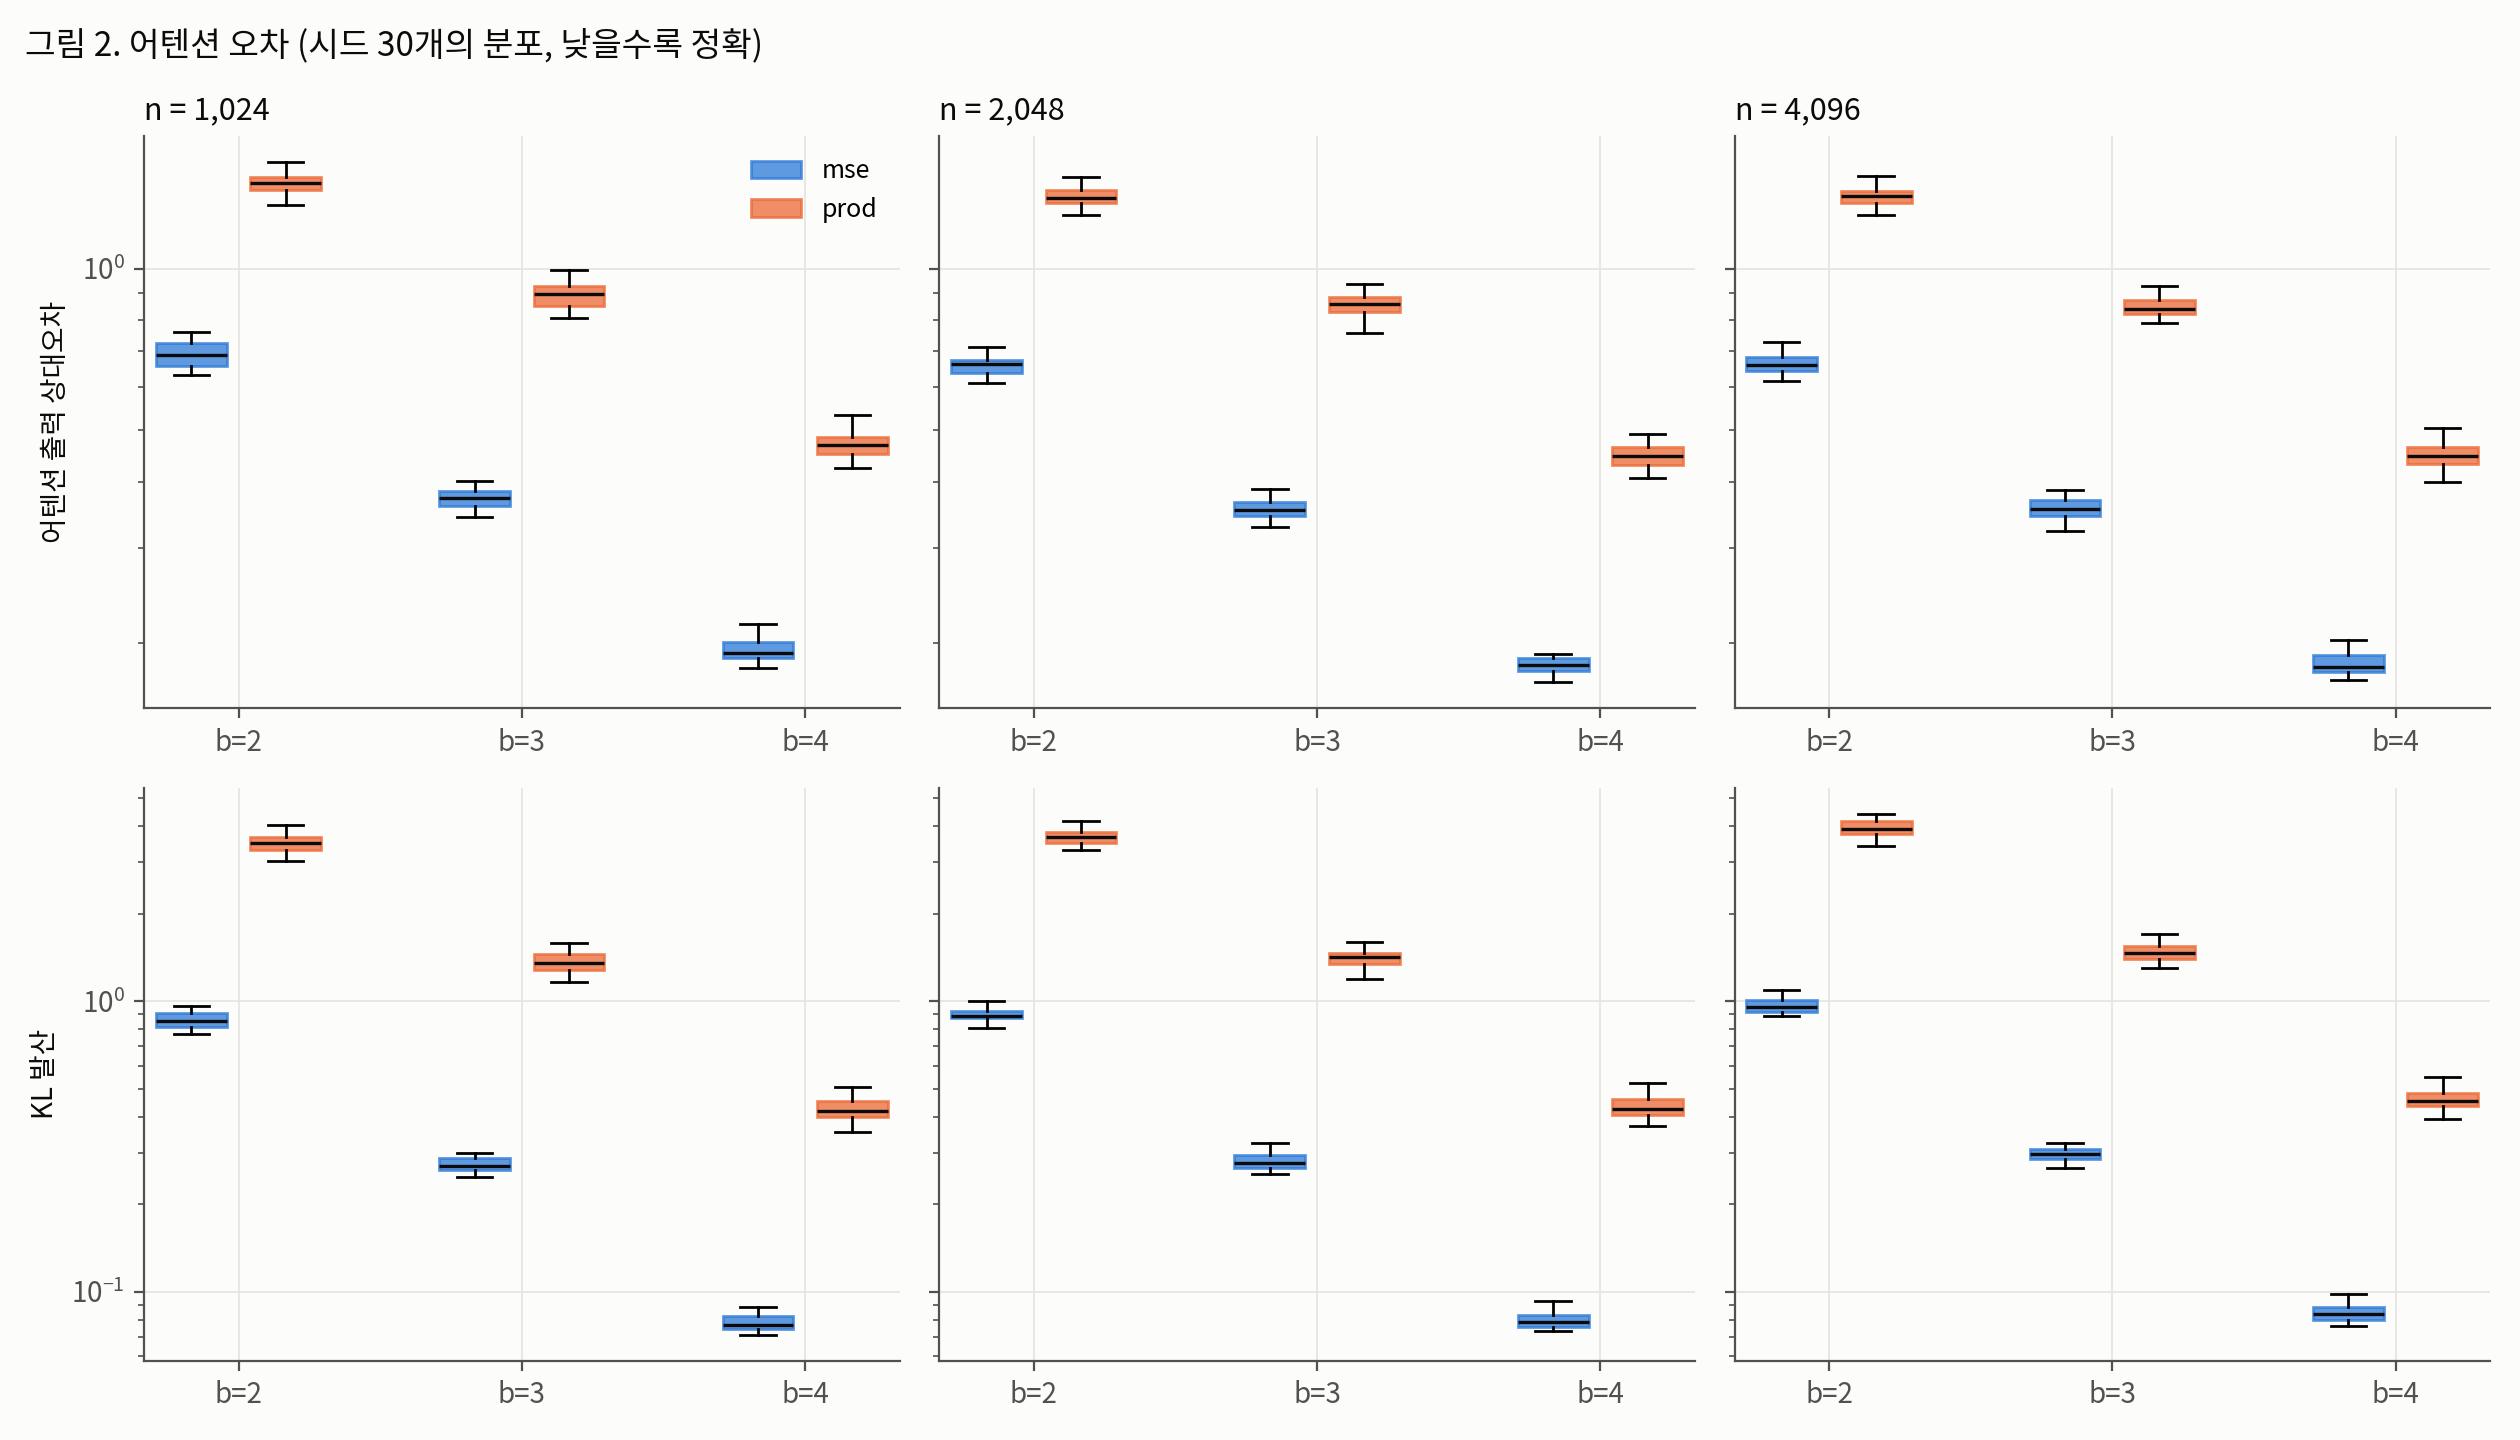

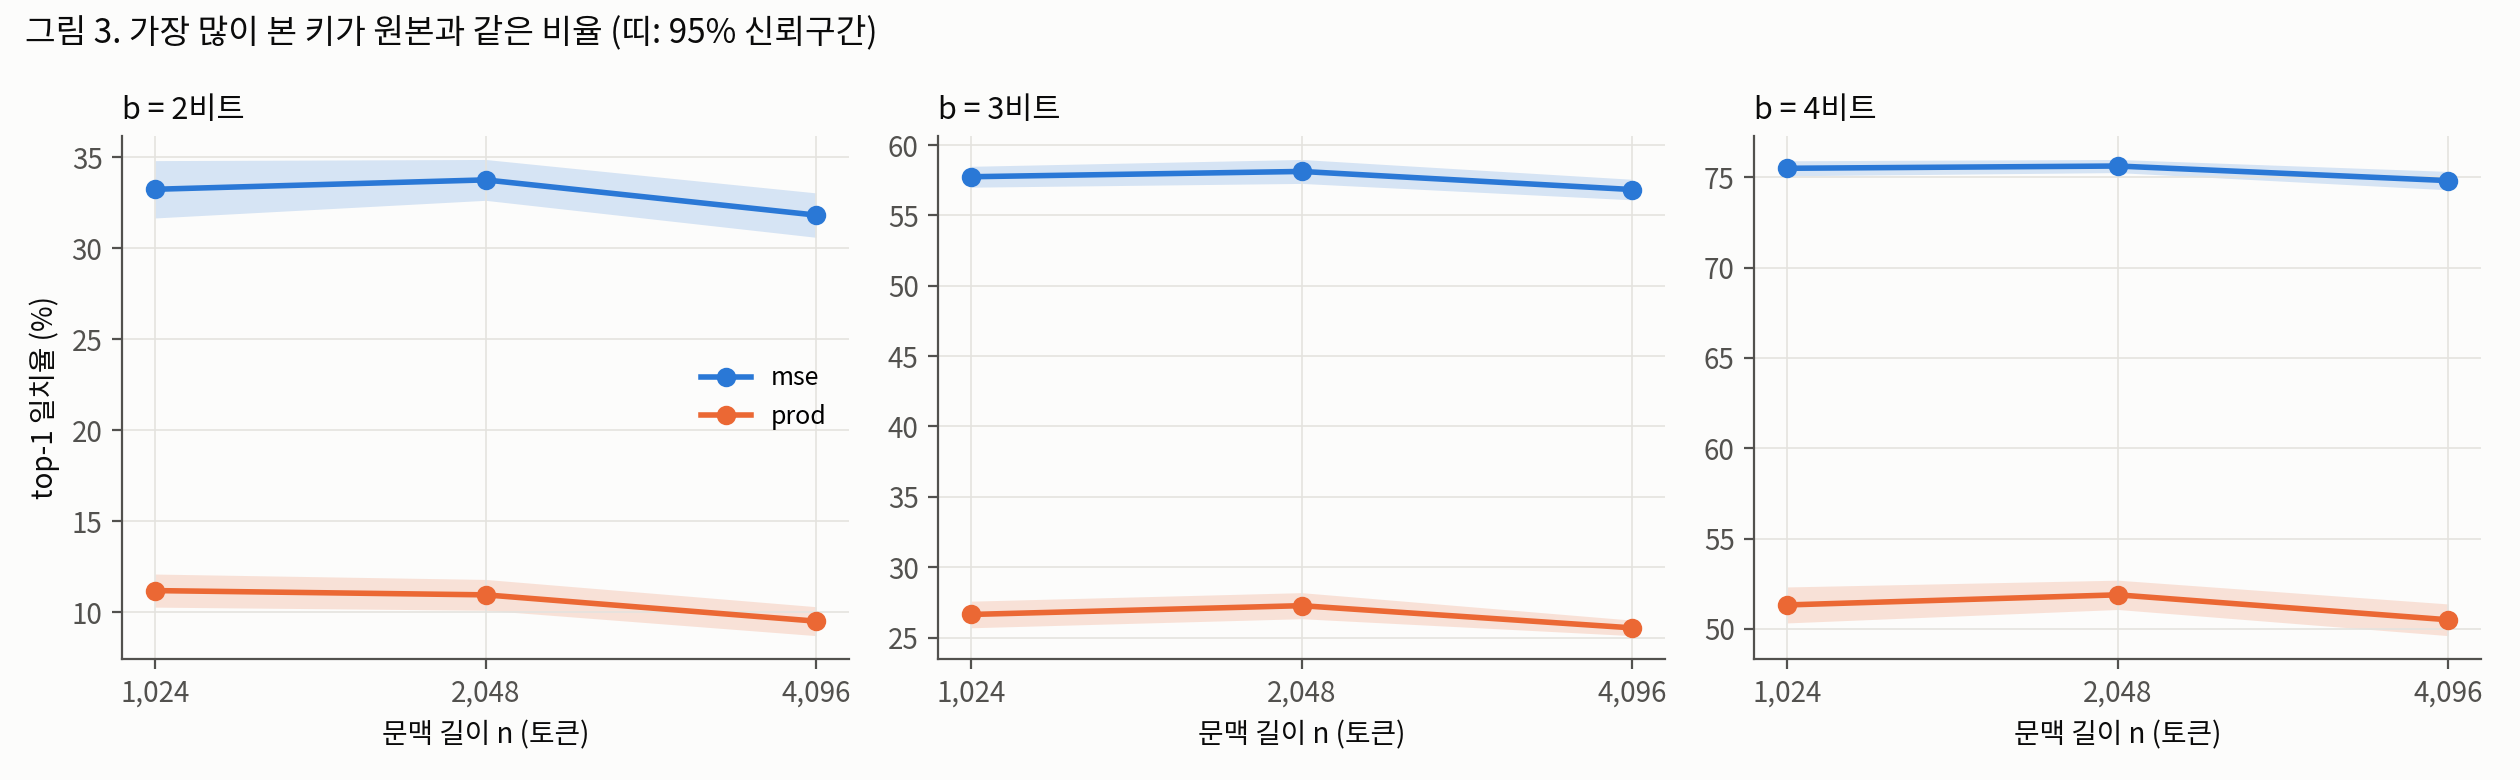

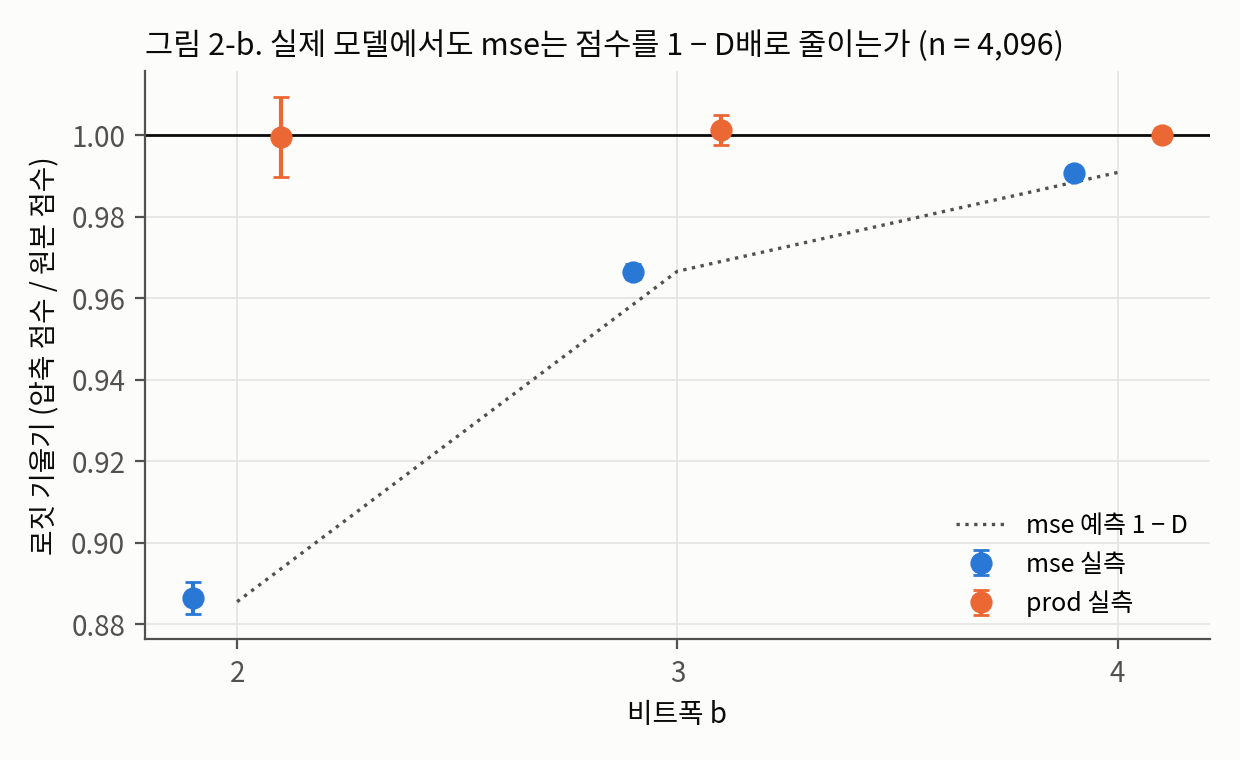

In [5]:
# 5) 그림 보기
from IPython.display import Image, display
display(Image('figures/fig2_attention_error.png', width=1000))
display(Image('figures/fig3_top1_vs_n.png', width=1000))
display(Image('figures/fig2b_logit_slope.png', width=650))

In [6]:
# 6) 판정 요약
!python summarize_exp2.py

 2단계 어텐션 실험 판정 요약   2단계 어텐션 실험
 모델 Qwen/Qwen2.5-0.5B  헤드 차원 64  층 [4, 12, 22]  시드 30개  장치 Tesla T4
 끼어들기 검사(기본 구현과의 출력 차이): 9.107589721679688e-05
 [0] 원본 어텐션의 성격 (압축 전)
   n=1,024  엔트로피 3.78  1등 키 가중치  26.2%  첫 토큰(어텐션 싱크)이 1등인 비율  37.8%
   n=2,048  엔트로피 3.96  1등 키 가중치  26.0%  첫 토큰(어텐션 싱크)이 1등인 비율  37.0%
   n=4,096  엔트로피 4.20  1등 키 가중치  25.5%  첫 토큰(어텐션 싱크)이 1등인 비율  36.1%
--------------------------------------------------------------------------------------
 [1] 조건별 비교 (prod − mse, 대응표본 t + 윌콕슨, 본페로니 0.0056)
  b      n |    출력오차 mse      prod    승자 |    KL mse      prod    승자 | top-1 mse   prod    승자
  2  1,024 |      0.6932    1.4407   mse |    0.8646    3.4950   mse |     33.2%  11.2%   mse
  2  2,048 |      0.6600    1.3622   mse |    0.9046    3.6803   mse |     33.7%  10.9%   mse
  2  4,096 |      0.6633    1.3662   mse |    0.9680    3.9389   mse |     31.8%   9.5%   mse
  3  1,024 |      0.3735    0.8928   mse |    0.2739    1.3656   mse |     57.7%  26.6%   mse
  3  2,048 |      